<a href="https://colab.research.google.com/github/oliviaberset/2026_solute_transport/blob/main/assignment_1_Annisa_Olivia_(1).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Solute transport in a small pre-Alpine catchment: the Erlenbach (Alptal) hydrochemistry 2021

Students : Berset Olivia & Kusumawardhani Nur Annisa

The goal of this assignment is to compare the two neighbouring sub-catchments of the Erlenbach, Chaspersboden (outlet CB1) and Langried (outlet L1). To do so, we analysed the chemistry of their stream and how they respond to rain events.

The analysis is organised in three parts:
1) The chemical signature of each water type in the two sub-catchments
2) The response of solutes to rain events
3) Going deeper: the response of the two sub-catchments over five rain events

## The data
The data come from Envidat. It is an hydrochemical dataset collected during spring-fall 2021 in the Erlenbach catchment (Alptal, near Zurich). Samples were taken hourly at the outlets of the Langried (`L1`) and Chaspersboden (`CB1`) sub-catchments during rain events, with rain (`E2`), soil water (lysimeters, `LYS`) and groundwater (piezometers, `GW`) sampled around the events. There is no discharge in this file.


Dataset: Bujak-Ozga, von Freyberg, Rinaldo and van Meerveld (2024), Hydrochemical data collected during spring-fall 2021 in the Erlenbach catchment, EnviDat, https://doi.org/10.16904/envidat.556.

**Summary dataset:**
| Group | Location IDs | Sampling |
|---|---|---|
| Outlets | **CB1** (Chaspersboden sub-catchment), **L1** (Langried sub-catchment) | about hourly during rain events |
| Rain | **E2** (Erlenhöhe) | hourly during events |
| Groundwater | IDs with `GW` (piezometers) | between events |
| Soil water | IDs ending in `LYS` (lysimeters next to the piezometers) | between events |
| Other stream points | CA*, CB*, L*, LA* | once (7 Sept), not used here |


### 1. Import the important libraries

In [ ]:
import io, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid")
RNG = np.random.default_rng(42)

## 2. Data import and tidying

We tidy the data with the following choices:
- Only solute concentrations are used.
- Values below the detection limit are written as text (e.g. `<0.015`, the number is the detection limit). We flag them and replace them by half the detection limit.
- The single baseflow survey of 7 September (stations CA*, CB2-CB8, L3, L14, L15, LA*) is not used here.

In [ ]:
data_path = os.path.join("data", "erlenbach_hydrochem_2021.csv")
assert os.path.exists(data_path), f"File not found: {data_path}. Run the notebook from the folder that contains 'data/'."

def read_erlenbach(path):
    """Read the EnviDat csv. Some exports wrap every line in quotes (one single column);
    in that case we remove the outer quotes first. A normal csv is read directly."""
    text = open(path, encoding="utf-8").read().replace("\r", "")
    lines = [l for l in text.split("\n") if l.strip()]
    if lines[0].startswith('"collected_at,'):
        lines = [l[1:-1].replace('""', '"') for l in lines]
    return pd.read_csv(io.StringIO("\n".join(lines)), parse_dates=["collected_at"])

df_raw = read_erlenbach(data_path)
print(df_raw.shape, "| columns:", list(df_raw.columns))
df_raw.head(3)

(13275, 5) | columns: ['collected_at', 'location_id', 'sample_id', 'type', 'value']


,collected_at,location_id,sample_id,type,value
0,2021-09-07 12:20:00,CA11,U321,Ca,63.592
1,2021-09-07 12:24:00,CA12,U322,Ca,68.121
2,2021-09-07 12:27:00,CA13,U323,Ca,71.532


In [ ]:
solutes = ["Ca", "Mg", "Na", "K", "Cl", "SO4", "NO3", "Si"]

# We only keep concentrations (not the uncertainties and not the isotope standard deviations)
df_long = df_raw[df_raw["type"].isin(solutes)].copy()

# The values below the detection limit are written as text, e.g. "<0.015": flag them and replace by LOD/2
val = df_long["value"].astype(str)
df_long["below_LOD"] = val.str.startswith("<")
df_long["value"] = pd.to_numeric(val.str.lstrip("<"))
df_long.loc[df_long["below_LOD"], "value"] = df_long.loc[df_long["below_LOD"], "value"] / 2

# one row per sample, one column per solute
df = (df_long.pivot_table(index=["location_id", "sample_id", "collected_at"], columns="type", values="value")
      .reset_index())

def site_group(loc):
    if loc in ["CB1", "L1"]: return "Outlet"
    if loc == "E2": return "Rain"
    if loc.endswith("LYS"): return "Soil water"
    if "GW" in loc: return "Groundwater"
    return "Other stream point"

df["group"] = df["location_id"].apply(site_group)
df["subcatchment"] = df["location_id"].str[0].map({"C": "Chaspersboden (C)", "L": "Langried (L)", "E": "-"})

df_other = df[df["group"] == "Other stream point"]    # single baseflow survey of 7 Sept (not used here)
df = df[df["group"] != "Other stream point"].copy()

print("Share of values below the detection limit [%]:")
display((df_long.groupby("type")["below_LOD"].mean() * 100).round(1).to_frame("% < LOD").T)
print("Number of samples per water type:")
display(df.groupby("group")["sample_id"].count().to_frame("n").T)


Share of values below the detection limit [%]:


type,Ca,Cl,K,Mg,NO3,Na,SO4,Si
% < LOD,4.8,1.7,19.1,4.8,10.2,6.9,0.6,12.0


Number of samples per water type:


group,Groundwater,Outlet,Rain,Soil water
n,66,399,80,92


---
### Activity 1: Chemical signature of each water type in the two sub-catchments
The goal of this first step is to compare the concentration of each solute in rain, soil water, groundwater and at the outlet, separately for each sub-catchment. We use boxplots (one figure per sub-catchment) and a table of the median concentrations, to have the precise number for the comparison.

We plot each solutes concentration against the water types, using boxplot.

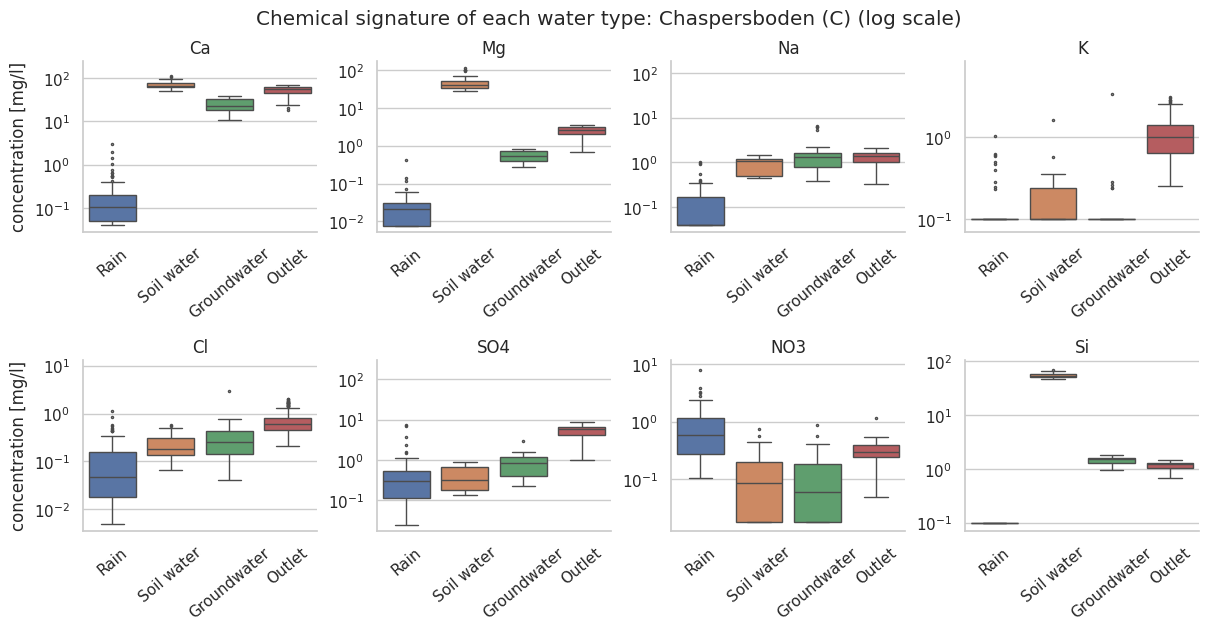

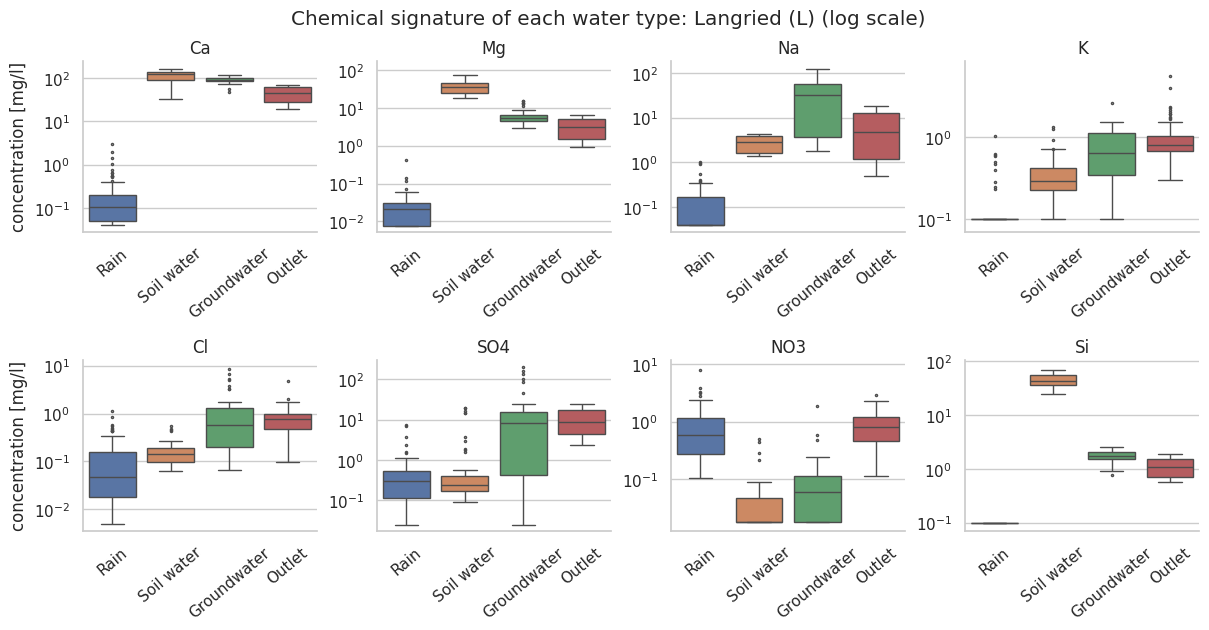

In [ ]:
order = ["Rain", "Soil water", "Groundwater", "Outlet"]

# Long format. Rain (E2) is a single station: it is shown in both figures as a reference.
df_plot = df.melt(id_vars=["location_id", "group", "subcatchment"], value_vars=solutes,
                  var_name="solute", value_name="concentration")

# Same y-axis range for the two sub-catchments
ylims = {s: (d["concentration"].min() * 0.7, d["concentration"].max() * 1.5)
         for s, d in df_plot.groupby("solute")}

def plot_signatures(subcatchment):
    d = df_plot[(df_plot["subcatchment"] == subcatchment) | (df_plot["group"] == "Rain")]
    g = sns.catplot(data=d, kind="box", x="group", y="concentration", col="solute", col_wrap=4,
                    order=order, hue="group", hue_order=order, sharex=False, sharey=False,
                    height=2.9, aspect=1.05, fliersize=1.5)
    for ax, s in zip(g.axes.flat, solutes):
        ax.set_yscale("log")
        ax.set_ylim(ylims[s])
        ax.tick_params(axis="x", labelbottom=True, rotation=40)
    g.set_axis_labels("", "concentration [mg/l]")
    g.set_titles("{col_name}")
    g.fig.suptitle(f"Chemical signature of each water type: {subcatchment} (log scale)", y=1.02)
    g.fig.subplots_adjust(hspace=0.75)
    plt.show()

plot_signatures("Chaspersboden (C)")
plot_signatures("Langried (L)")

**Median composition**

The boxplots give a visual impression, while the table below gives the corresponding numbers. For each water type, the median concentration of each solute is computed. The median (the middle value) is used instead of the mean because it is not affected by a few extreme samples.

The table is also split by sub-catchment (C = Chaspersboden, L = Langried), because the boxplots showed a large spread in groundwater that may come from differences between the two sub-catchments.


In [ ]:
# Median composition by water type and sub-catchment
df.groupby(["group", "subcatchment"])[solutes].median().round(2)

type                               Ca     Mg     Na     K    Cl   SO4   NO3  \
group       subcatchment                                                      
Groundwater Chaspersboden (C)   22.62   0.53   1.34  0.10  0.25  0.85  0.06   
            Langried (L)        89.17   5.32  31.77  0.65  0.57  8.12  0.06   
Outlet      Chaspersboden (C)   57.42   2.68   1.36  1.01  0.60  5.77  0.30   
            Langried (L)        46.46   3.12   4.86  0.80  0.75  8.74  0.80   
Rain        -                    0.11   0.02   0.04  0.10  0.05  0.31  0.60   
Soil water  Chaspersboden (C)   65.87  39.50   1.05  0.10  0.18  0.33  0.08   
            Langried (L)       122.63  35.27   2.80  0.30  0.14  0.24  0.02   

type                              Si  
group       subcatchment              
Groundwater Chaspersboden (C)   1.55  
            Langried (L)        1.72  
Outlet      Chaspersboden (C)   1.23  
            Langried (L)        1.07  
Rain        -                   0.10  
Soil water  Chaspersboden (C)  53.49  
            Langried (L)       43.74

**Chloride enrichment**

 To quantify the enrichment of chloride from rain to stream, the median chloride concentration at each outlet is divided by the median chloride concentration in rain. A ratio close to 1 would mean that stream chloride can be explained by rain alone, while a ratio above 1 indicates evapoconcentration and/or dry deposition.

In [ ]:
cl_rain = df.loc[df["group"] == "Rain", "Cl"].median()
cl_out = df[df["group"] == "Outlet"].groupby("location_id")["Cl"].median()
print(f"Median Cl in rain: {cl_rain:.2f} mg/l")
for loc, v in cl_out.items():
    print(f"Median Cl at {loc}: {v:.2f} mg/l  ->  {v / cl_rain:.0f} times the rain")

Median Cl in rain: 0.05 mg/l
Median Cl at CB1: 0.59 mg/l  ->  12 times the rain
Median Cl at L1: 0.75 mg/l  ->  16 times the rain


### Activity 1: Observations
Rain (station E2, same for both sub-catchments)
- Ca, Mg, Na, K and Si are much lower than at the outlets (CB1, L1). For example, median Ca is 0.11 mg/l in rain against 46-57 mg/l at the outlets.
- All Si values and most K values are below the detection limit and were replaced by half of it. They only show that rain contains very little of these solutes.
- Nitrate is the only solute as concentrated in rain (0.60 mg/l) as in the streams.

Soil water (similar in both sub-catchments)
- Very rich in Mg (about 35-40 mg/l) and Si (about 44-53 mg/l).
- High Ca: 66 mg/l at Chaspersboden and 123 mg/l at Langried.
- Very low SO4 (0.2-0.3 mg/l) and NO3 (0.02-0.08 mg/l).

Groundwater (strong difference between sub-catchments)
- Langried is much more mineralised than Chaspersboden:
  - Na: 32 against 1.3 mg/l
  - SO4: 8.1 against 0.85 mg/l
  - Ca: 89 against 23 mg/l
  - Mg: 5.3 against 0.5 mg/l
- NO3 is very low in both (0.06 mg/l).

Outlets
- For most solutes they lie between rain and the stored waters, as expected for a mixture.
- They follow the groundwater difference. Langried has more Na (4.9 against 1.4 mg/l) and SO4 (8.7 against 5.8 mg/l) than Chaspersboden.
- Nitrate is higher at Langried (0.80 against 0.30 mg/l), although soil water and groundwater contain very little nitrate.



---
### Activity 2: The response of solutes to rain events

Since there is no discharge data Ca is a used as an indicator of how much rain water is in the stream. It is high at baseflow and drops strongly during events (rain has almost no Ca). Here we want to look at which solutes follow Ca (diluted), and which behave the opposite way (mobilised during events).

To compare solutes with different units and ranges, we normalise each one per outlet (subtract the mean and divide by the standard deviation).

**Scatter plots against Ca**

Each solute is plotted against Ca for all outlet samples. If a solute is diluted by rain water in the same way as Ca, its points rise from left to right; if it is mobilised during events, its points fall from left to right.



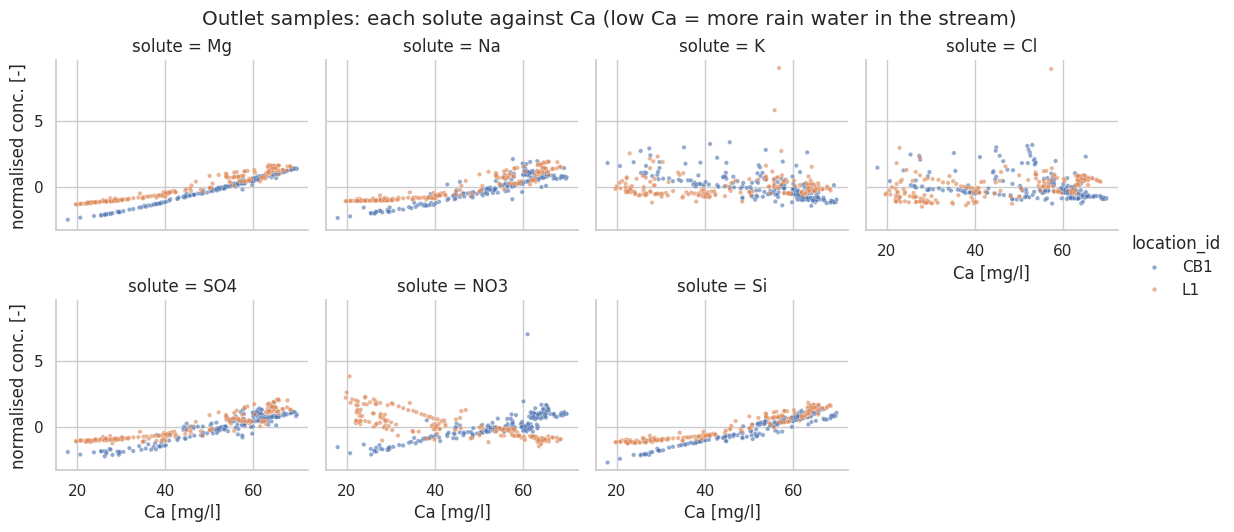

In [ ]:
# Outlet samples only
df_out = df[df["group"] == "Outlet"].copy()

# Normalise each solute per outlet: (x - mean) / std
def normalize(x):
    return (x - x.mean()) / x.std()

for s in solutes:
    df_out[s + "_norm"] = df_out.groupby("location_id")[s].transform(normalize)

# Long format: every solute against Ca
others = [s for s in solutes if s != "Ca"]
df_cc = pd.melt(df_out, id_vars=["location_id", "collected_at", "Ca"],
                value_vars=[s + "_norm" for s in others], var_name="solute", value_name="norm_conc")
df_cc["solute"] = df_cc["solute"].str.replace("_norm", "")

g = sns.relplot(
    data=df_cc, kind="scatter",
    x="Ca", y="norm_conc", col="solute", col_wrap=4, hue="location_id",
    s=10, alpha=0.6, height=2.6, aspect=1.1,
)
g.set_axis_labels("Ca [mg/l]", "normalised conc. [-]")
g.fig.suptitle("Outlet samples: each solute against Ca (low Ca = more rain water in the stream)", y=1.02)
plt.show()

To classify the solutes objectively, the correlation between each solute and Ca is computed for each outlet, using the Spearman (rank) correlation.

In [ ]:
corr_ca = pd.DataFrame({
    loc: {s: stats.spearmanr(d["Ca"], d[s], nan_policy="omit").statistic for s in others}
    for loc, d in df_out.groupby("location_id")
}).round(2)
corr_ca.T

,Mg,Na,K,Cl,SO4,NO3,Si
CB1,0.99,0.85,-0.75,-0.53,0.87,0.89,0.94
L1,0.97,0.95,0.12,0.50,0.93,-0.86,0.96


**Event figure.**

The following figure shows the evolution of the normalised concentrations of Ca, Si, SO4, NO3 and K at the two sites (CB1 and L1) from 15 to 21 September 2021. These events were selected because:

- the strongest events in the record at both outlets;
- being only three days apart, they also show how the first event affects the second.

How the figure is built:

- **Solutes:** Ca, Si and SO4 represent the diluted (geogenic) solutes; NO3 and K represent the solutes that can be mobilised from the topsoil.
- **Y-axis:** the normalised concentrations from above are used (0 = the mean of that solute at that outlet, +1 / −1 = one standard deviation above/below the mean), so that all solutes can be shown on one axis.
- **No interpolation:** Between the two dates, sampling is sparse (grey band), we chose not to interpolate the data across this period, and instead present a close-up in a separate figure to show the evolution over time (in hours) during the two events.

The tables and summary values, in contrast, are computed from all samples of all events.

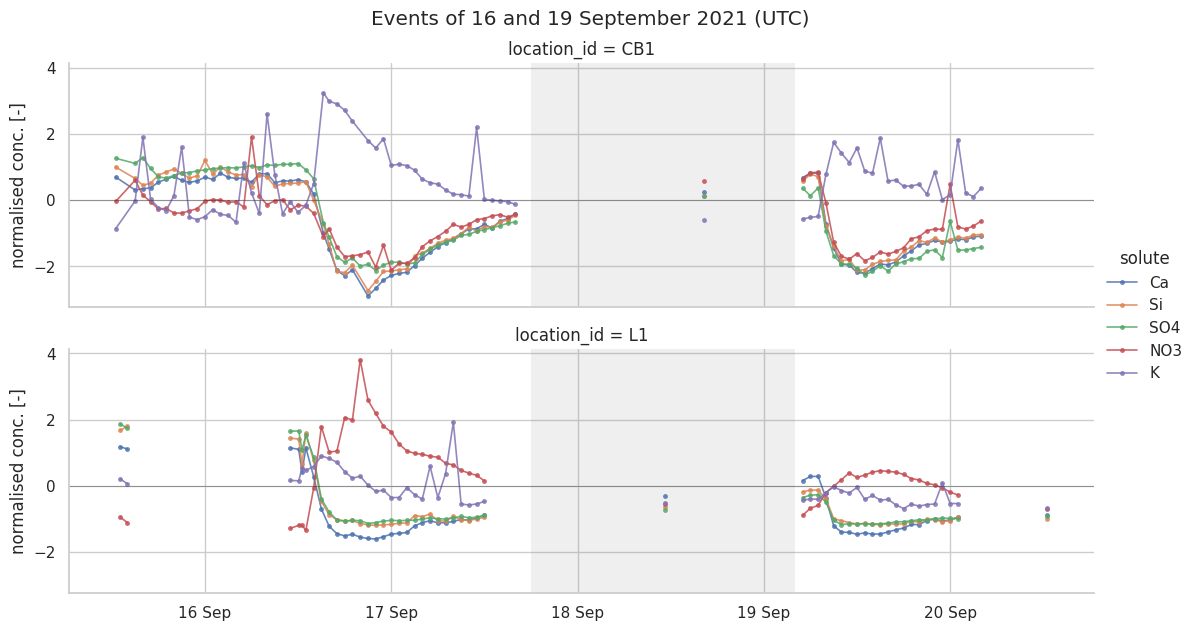

In [ ]:
import matplotlib.dates as mdates

q = (df_out["collected_at"] >= "2021-09-15 12:00") & (df_out["collected_at"] < "2021-09-21")
show = ["Ca", "Si", "SO4", "NO3", "K"]
df_ts = pd.melt(df_out[q], id_vars=["location_id", "collected_at"],
                value_vars=[s + "_norm" for s in show], var_name="solute", value_name="norm_conc")
df_ts["solute"] = df_ts["solute"].str.replace("_norm", "", regex=False)

df_ts = df_ts.sort_values(["location_id", "solute", "collected_at"])
keys = [df_ts["location_id"], df_ts["solute"]]
gap = df_ts.groupby(keys)["collected_at"].diff() > pd.Timedelta("6h")
df_ts["segment"] = gap.groupby(keys).cumsum()

g = sns.relplot(
    data=df_ts, kind="line",
    x="collected_at", y="norm_conc", hue="solute", hue_order=show,
    units="segment", estimator=None, row="location_id",
    height=3.2, aspect=3.5,
    lw=1.2, alpha=0.85, marker="o", markersize=3.5, markeredgewidth=0,
)
for ax in g.axes.flat:
    ax.axhline(0, color="k", lw=0.6, alpha=0.4)
    ax.axvspan(pd.Timestamp("2021-09-17 18:00"), pd.Timestamp("2021-09-19 04:00"),
               color="grey", alpha=0.12, lw=0)          # sparse sampling period
    ax.xaxis.set_major_locator(mdates.DayLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))

g.set_axis_labels("", "normalised conc. [-]")
g.fig.suptitle("Events of 16 and 19 September 2021 (UTC)", y=1.02)
plt.show()

Close up:

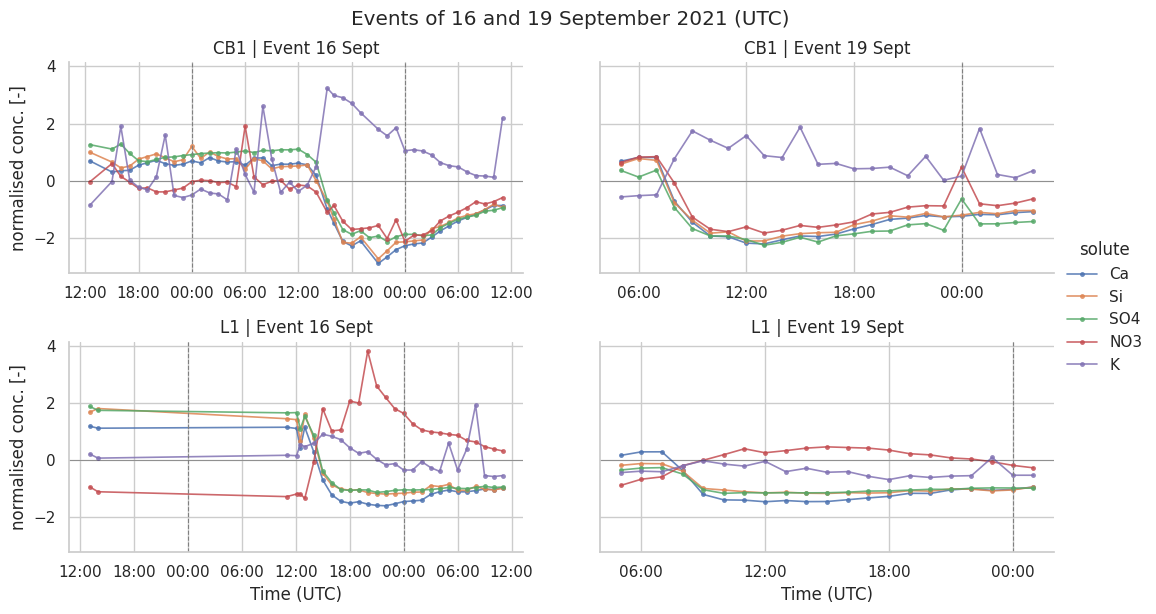

In [ ]:
import matplotlib.dates as mdates

events = {
    "Event 16 Sept": ("2021-09-15 12:00", "2021-09-17 12:00"),
    "Event 19 Sept": ("2021-09-19 00:00", "2021-09-20 06:00"),
}

show = ["Ca", "Si", "SO4", "NO3", "K"]
parts = []
for name, (t0, t1) in events.items():
    m = (df_out["collected_at"] >= t0) & (df_out["collected_at"] < t1)
    d = pd.melt(df_out[m], id_vars=["location_id", "collected_at"],
                value_vars=[s + "_norm" for s in show],
                var_name="solute", value_name="norm_conc")
    d["event"] = name
    parts.append(d)

df_ts = pd.concat(parts)
df_ts["solute"] = df_ts["solute"].str.replace("_norm", "", regex=False)
df_ts = df_ts.sort_values(["location_id", "event", "solute", "collected_at"])

g = sns.relplot(
    data=df_ts, kind="line",
    x="collected_at", y="norm_conc", hue="solute", hue_order=show,
    row="location_id", col="event",
    height=3.0, aspect=1.8,
    lw=1.2, alpha=0.85, marker="o", markersize=3.5, markeredgewidth=0,
    facet_kws=dict(sharex=False, sharey=True),
)

for ax in g.axes.flat:
    ax.axhline(0, color="k", lw=0.6, alpha=0.4)
    ax.xaxis.set_major_locator(mdates.HourLocator(byhour=range(0, 24, 6)))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))

    # dashed line at each midnight, to show where the day changes
    lo, hi = [mdates.num2date(x).replace(tzinfo=None) for x in ax.get_xlim()]
    for day in pd.date_range(lo.date(), hi.date(), freq="D")[1:]:
        if lo < day < hi:
            ax.axvline(day, color="grey", ls="--", lw=0.8)

g.set_axis_labels("Time (UTC)", "normalised conc. [-]")
g.set_titles("{row_name} | {col_name}")
g.fig.suptitle("Events of 16 and 19 September 2021 (UTC)", y=1.02)
plt.show()

### Activity 2: Discussion

Two groups of solutes appear:

- **Diluted during events:** **Mg, Si, Na and SO4** correlate strongly and positively with Ca at both outlets (ρ ≈ 0.85–0.99). They possibly come from mineral weathering in the soil and bedrock and are highest in pre-event water. When rain water arrives, they are all diluted together.
- **Higher during events:**
  - **K** at CB1 (ρ = −0.75, cf. spearman correlation) rises during events. K  probably comes from the organic matter in the soil, washed into the stream by the rain.
  - **NO3** at L1 (ρ = −0.86, cf. spearman correlation) also rises during events. Nitrate in the topsoil is mobilized by the event water.   
  - **Cl** at CB1 (ρ = −0.53, cf. spearman correlation) also increases slightly during events, which suggests Cl stored in the topsoil or deposited on vegetation is washed out.
- **The two sub-catchments differ for nitrate, K and Cl.** At CB1, NO3 is diluted like Ca (ρ = 0.89) and falls below the rain concentration, so rain nitrate is probably taken up in the soil. At L1 it is mobilised. K and Cl also differ: they rise during events at CB1, but at L1 K shows no clear relation with Ca (ρ = 0.12) and Cl is moderately diluted (ρ = +0.50). The same solute can therefore be removed in one sub-catchment and flushed in the other, depending on flow paths and soil conditions.

- **The response is fast**: concentrations change within 1–2 hours of the rain and partly recover over the following day. This means the event water reaches the stream along shallow flow paths.

---
### Activity 3: Going deeper – response over five rain events

Activity 2 focused on the events of 16 and 19 September. To check that the contrast between the two sub-catchments is not specific to these two events, we look at the five events with hourly sampling. Ca is used as a tracer of rain water (it drops when rain arrives). The dashed line is the nitrate concentration expected if the stream were a simple mixture of pre-event water and rain: a measured value above the dashed line means that nitrate is added, and below it that nitrate is removed.

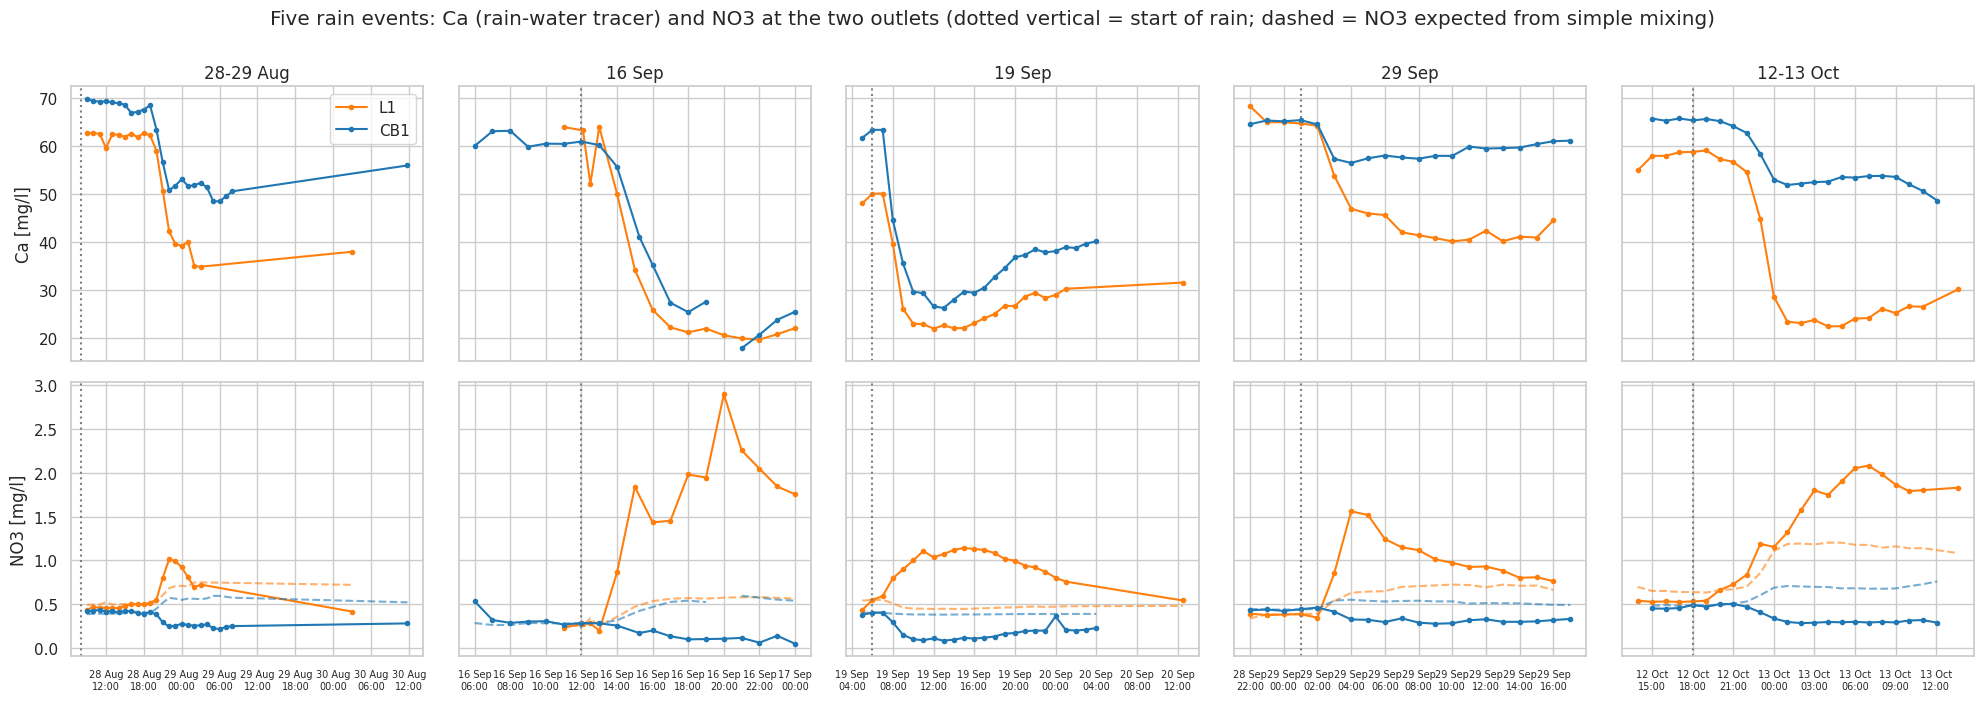

In [ ]:
import matplotlib.dates as mdates

# Rain start = first rain sample (E2) of each event; window = time range shown
events5 = {
    "28-29 Aug": ("2021-08-28 08:00", "2021-08-30 12:00", "2021-08-28 08:00"),
    "16 Sep":    ("2021-09-16 06:00", "2021-09-17 00:00", "2021-09-16 12:00"),
    "19 Sep":    ("2021-09-19 03:00", "2021-09-20 13:00", "2021-09-19 06:00"),
    "29 Sep":    ("2021-09-28 22:00", "2021-09-29 18:00", "2021-09-29 01:00"),
    "12-13 Oct": ("2021-10-12 13:00", "2021-10-13 14:00", "2021-10-12 18:00"),
}
Ca_rain = df.loc[df["group"] == "Rain", "Ca"].median()
colors = {"L1": "tab:orange", "CB1": "tab:blue"}

fig, axes = plt.subplots(2, len(events5), figsize=(20, 7), sharey="row")
for j, (name, (t0, t1, t_rain)) in enumerate(events5.items()):
    rain = df[(df["group"] == "Rain") & (df["collected_at"] >= t0) & (df["collected_at"] <= t1)]
    NO3_rain = rain["NO3"].mean()                      # mean nitrate in the rain of the event
    for loc in ["L1", "CB1"]:
        x = (df_out[(df_out["location_id"] == loc) & (df_out["collected_at"] >= t0)
                    & (df_out["collected_at"] <= t1)].sort_values("collected_at"))
        # pre-event baseline: median of up to 5 samples before the first clear drop of Ca (> 8 %)
        k0 = np.where(x["Ca"].values < 0.92 * x["Ca"].values[0])[0]
        k0 = k0[0] if len(k0) else 1
        pre = x.iloc[max(0, k0 - 5):max(1, k0)]
        Ca_pre, NO3_pre = pre["Ca"].median(), pre["NO3"].median()
        f_event = (Ca_pre - x["Ca"]) / (Ca_pre - Ca_rain)        # share of rain water (Ca as tracer)
        NO3_expected = (1 - f_event) * NO3_pre + f_event * NO3_rain  # simple mixing
        axes[0, j].plot(x["collected_at"], x["Ca"], "-o", ms=3, color=colors[loc], label=loc)
        axes[1, j].plot(x["collected_at"], x["NO3"], "-o", ms=3, color=colors[loc])
        axes[1, j].plot(x["collected_at"], NO3_expected, "--", color=colors[loc], alpha=0.6)
    for ax in axes[:, j]:
        ax.axvline(pd.Timestamp(t_rain), color="grey", ls=":")
    axes[0, j].set_title(name)
    axes[0, j].tick_params(axis="x", labelbottom=False)
    axes[1, j].xaxis.set_major_formatter(mdates.DateFormatter("%d %b\n%H:%M"))
    axes[1, j].tick_params(axis="x", labelsize=7)

axes[0, 0].set_ylabel("Ca [mg/l]"); axes[1, 0].set_ylabel("NO3 [mg/l]")
axes[0, 0].legend()
fig.suptitle("Five rain events: Ca (rain-water tracer) and NO3 at the two outlets "
             "(dotted vertical = start of rain; dashed = NO3 expected from simple mixing)", y=1.0)
fig.tight_layout()
plt.show()

### Activity 3: Discussion

- **Both sub-catchments are diluted by rain in every event**, as shown by the drop of Ca. The dilution is stronger at L1 in four of the five events. The two sub-catchments respond similarly only on 16 and 19 September, the two biggest events, when the catchments were very wet.
- **Nitrate shows the same contrast in all five events.** At L1 it is always above the expected mixing line (up to 2.9 mg/l on 16 September), so nitrate is added to the stream. At CB1 it stays flat or falls below the line, so nitrate is removed or diluted more than expected.
- The nitrate contrast between the two sub-catchments is therefore not specific to the two events of Activity 2, but a consistent feature of their response to rain.

### Final conclusion

The two neighbouring sub-catchments of the Erlenbach respond differently to rain, even though they receive the same rain.

- **Stored water differs (Activity 1).** Groundwater is much more mineralised at Langried than at Chaspersboden (e.g. Na 32 against 1.3 mg/l), and the outlets follow this difference. Nitrate is higher at Langried (0.80 against 0.30 mg/l) although soil water and groundwater contain very little.
- **Most solutes behave alike (Activity 2).** Mg, Si, Na and SO4 are diluted by rain together with Ca at both outlets.
- **Nitrate, K and Cl behave differently (Activity 2).** At Langried nitrate is mobilised during events, while at Chaspersboden it is diluted like Ca. K rises at Chaspersboden but not at Langried.
- **The contrast is consistent (Activity 3).** Over five events, nitrate at Langried is always above the concentration expected from simple mixing, whereas at Chaspersboden it stays flat or falls below it.

These results suggest that the two sub-catchments differ in where the event water comes from and which flow paths it follows.

# Limitations
- The file has no discharge, so we cannot compute loads or C–Q relationships.
- Many rain values (Ca and Mg 40 %, Si 100 %) are below the detection limit and replaced by LOD/2.
- Only five events are analysed, in one very wet summer (2021), so the results are indicative.
